In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import randint, loguniform, uniform
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.datasets import make_classification

%matplotlib inline

RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
N_ITER = 40

В начале работы зафиксированы константы (`RANDOM_STATE` = 42, `TEST_SIZE` = 0.2, `CV_FOLDS` = 5, `N_ITER` = 40) для полной воспроизводимости результатов.

In [3]:
df = pd.read_csv('Titanic-Dataset.csv')
print(df.shape)
print(f'Количество дубликатов: {df.duplicated().sum()}')
df.head()

(891, 12)
Количество дубликатов: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Рассматривается задача бинарной классификации выживаемости пассажиров (признак `Survived`) на датасете Titanic (891 объект, 12 признаков, полных дубликатов нет).
Для оценки качества используется `F1-score`, так как классы несбалансированы и важно одновременно учитывать точность (`Precision`) и полноту (`Recall`).

In [4]:
class TitanicFeatures(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        X_tmp = self._add_base_features(X)

        self.age_medians_ = X_tmp.groupby(['Title', 'Pclass'])['Age'].median()
        self.global_age_median_ = X_tmp['Age'].median()

        return self

    def transform(self, X):
        X = self._add_base_features(X)

        medians_series = X.set_index(['Title', 'Pclass']).index.map(self.age_medians_)

        X['Age'] = (
            X['Age']
            .fillna(pd.Series(medians_series, index=X.index))
            .fillna(self.global_age_median_)
        )

        return X

    def _add_base_features(self, X):
        X = X.copy()

        X['Title'] = X['Name'].str.extract(r'([A-Za-z]+)\.')
        X['Title'] = X['Title'].replace(['Mlle', 'Ms'], 'Miss').replace('Mme', 'Mrs')
        X.loc[~X['Title'].isin(['Miss', 'Mr', 'Mrs', 'Master']), 'Title'] = 'Rare'

        X['deck'] = X['Cabin'].str[0].fillna('U')

        return X

X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)


In [5]:
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']
cat_cols = ['Pclass', 'Sex', 'Embarked', 'Title', 'deck']

preprocess = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols)
])

gb_base = Pipeline([
    ('features', TitanicFeatures()),
    ('prep', preprocess),
    ('model', GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=RANDOM_STATE
    ))
])

t0 = time.perf_counter()
base_cv_scores = cross_val_score(gb_base, X_train, y_train, cv=CV_FOLDS, scoring='f1', n_jobs=-1)
base_time = time.perf_counter() - t0

print(f"Baseline CV F1: {base_cv_scores.mean():.4f} ± {base_cv_scores.std():.4f} (время: {base_time:.2f} сек)")

Baseline CV F1: 0.7405 ± 0.0552 (время: 8.15 сек)


In [6]:
param_grid = {
    'model__n_estimators': [50, 100, 150, 200],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__max_depth': [1, 2, 3],
    'model__subsample': [0.8, 1.0]
}

t0 = time.perf_counter()
grid = GridSearchCV(
    estimator=gb_base,
    param_grid=param_grid,
    scoring='f1',
    cv=CV_FOLDS,
    n_jobs=-1
)
grid.fit(X_train, y_train)
grid_time = time.perf_counter() - t0

print(f"Лучшие параметры Grid Search: {grid.best_params_}")
print(f"Лучший CV F1: {grid.best_score_:.4f}, время: {grid_time:.2f} сек")

grid_results = pd.DataFrame(grid.cv_results_)
grid_results[[
    'params',
    'mean_test_score',
    'std_test_score',
    'mean_fit_time',
]].sort_values('mean_test_score', ascending=False).head(10)

Лучшие параметры Grid Search: {'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__n_estimators': 200, 'model__subsample': 1.0}
Лучший CV F1: 0.7645, время: 88.68 сек


,params,mean_test_score,std_test_score,mean_fit_time
55,"{'model__learning_rate': 0.1, 'model__max_dept...",0.764527,0.044377,0.803173
50,"{'model__learning_rate': 0.1, 'model__max_dept...",0.762507,0.035560,0.232385
53,"{'model__learning_rate': 0.1, 'model__max_dept...",0.761776,0.035886,0.309002
30,"{'model__learning_rate': 0.05, 'model__max_dep...",0.761022,0.038280,0.482350
52,"{'model__learning_rate': 0.1, 'model__max_dept...",0.760022,0.033840,0.338221
31,"{'model__learning_rate': 0.05, 'model__max_dep...",0.758688,0.035591,0.400224
29,"{'model__learning_rate': 0.05, 'model__max_dep...",0.756948,0.029930,0.318850
71,"{'model__learning_rate': 0.1, 'model__max_dept...",0.756854,0.049687,0.646707
51,"{'model__learning_rate': 0.1, 'model__max_dept...",0.756837,0.036796,0.522367
69,"{'model__learning_rate': 0.1, 'model__max_dept...",0.755826,0.056535,0.822029


In [7]:
param_dist = {
    'model__n_estimators': randint(50, 250),
    'model__learning_rate': loguniform(0.01, 0.2),
    'model__max_depth': randint(1, 4),
    'model__subsample': uniform(0.75, 0.25)
}

t0 = time.perf_counter()
random_search = RandomizedSearchCV(
    estimator=gb_base,
    param_distributions=param_dist,
    n_iter=N_ITER,
    scoring='f1',
    cv=CV_FOLDS,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
random_search.fit(X_train, y_train)
random_time = time.perf_counter() - t0

print(f"Лучшие параметры Random Search: {random_search.best_params_}")
print(f"Лучший CV F1: {random_search.best_score_:.4f}, время: {random_time:.2f} сек")

random_results = pd.DataFrame(random_search.cv_results_)
random_results[[
    'params',
    'mean_test_score',
    'std_test_score',
    'mean_fit_time',
]].sort_values('mean_test_score', ascending=False).head(10)

Лучшие параметры Random Search: {'model__learning_rate': np.float64(0.05477661047824165), 'model__max_depth': 1, 'model__n_estimators': 240, 'model__subsample': np.float64(0.9605711936487497)}
Лучший CV F1: 0.7644, время: 59.42 сек


,params,mean_test_score,std_test_score,mean_fit_time
15,"{'model__learning_rate': 0.05477661047824165, ...",0.764392,0.038815,0.858391
4,"{'model__learning_rate': 0.16637391143003455, ...",0.760772,0.049802,0.662217
1,"{'model__learning_rate': 0.060099747183803134,...",0.759575,0.043577,0.576748
37,"{'model__learning_rate': 0.11233209577485018, ...",0.758794,0.041755,0.737270
32,"{'model__learning_rate': 0.08033176163139732, ...",0.754880,0.032201,0.463626
17,"{'model__learning_rate': 0.08834921226320053, ...",0.754392,0.057457,0.865111
20,"{'model__learning_rate': 0.18022959559673618, ...",0.753341,0.040731,0.235636
38,"{'model__learning_rate': 0.019794771074932348,...",0.753290,0.059149,0.511837
35,"{'model__learning_rate': 0.06490876477881215, ...",0.751903,0.052785,0.782045
14,"{'model__learning_rate': 0.07277150634170934, ...",0.751786,0.044660,0.510047


In [8]:
def summarize_search(name, search, elapsed_time):
    best_idx = search.best_index_
    return {
        'search': name,
        'n_combinations': len(search.cv_results_['params']),
        'time_sec': round(elapsed_time, 2),
        'best_cv_f1': search.best_score_,
        'std_cv_f1': search.cv_results_['std_test_score'][best_idx],
        'best_params': search.best_params_
    }

summary = pd.DataFrame([
    summarize_search('Grid Search', grid, grid_time),
    summarize_search('Random Search', random_search, random_time)
])
summary

,search,n_combinations,time_sec,best_cv_f1,std_cv_f1,best_params
0,Grid Search,72,88.68,0.764527,0.044377,"{'model__learning_rate': 0.1, 'model__max_dept..."
1,Random Search,40,59.42,0.764392,0.038815,"{'model__learning_rate': 0.05477661047824165, ..."


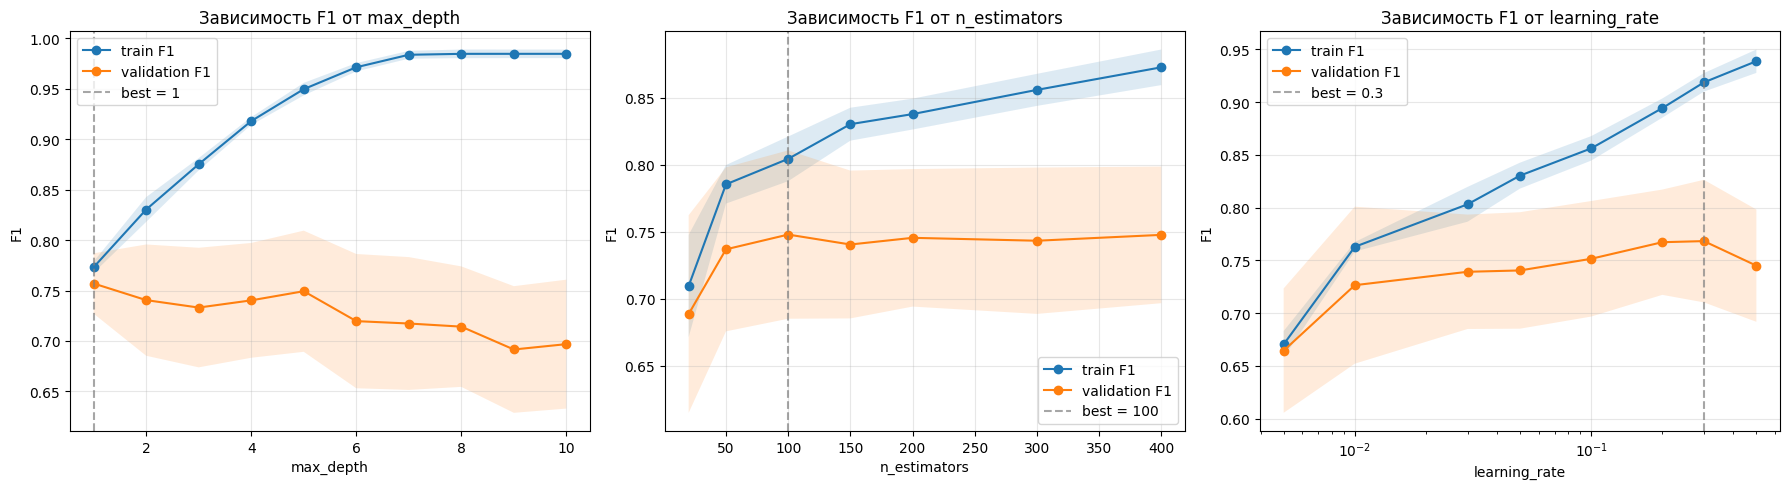

In [9]:
param_configs = [
    ("model__max_depth", np.arange(1, 11), "max_depth", False),
    ("model__n_estimators", [20, 50, 100, 150, 200, 300, 400], "n_estimators", False),
    ("model__learning_rate", [0.005, 0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5], "learning_rate", True),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (param_name, param_range, title, use_log) in zip(axes, param_configs):
    train_scores, val_scores = validation_curve(
        gb_base,
        X_train,
        y_train,
        param_name=param_name,
        param_range=param_range,
        cv=CV_FOLDS,
        scoring="f1",
        n_jobs=-1,
    )

    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)

    ax.plot(param_range, train_mean, marker="o", label="train F1")
    ax.fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.15)

    ax.plot(param_range, val_mean, marker="o", label="validation F1")
    ax.fill_between(param_range, val_mean - val_std, val_mean + val_std, alpha=0.15)

    if use_log:
        ax.set_xscale("log")

    best_idx = np.argmax(val_mean)
    ax.axvline(param_range[best_idx], color="grey", linestyle="--", alpha=0.7, label=f"best = {param_range[best_idx]}")

    ax.set_title(f"Зависимость F1 от {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("F1")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

Fold,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std,Min,Max
Baseline,0.711538,0.666667,0.788991,0.818182,0.716981,0.740472,0.055189,0.666667,0.818182
Grid Search Best,0.740741,0.693069,0.800000,0.818182,0.770642,0.764527,0.044377,0.693069,0.818182
Random Search Best,0.745455,0.712871,0.800000,0.818182,0.745455,0.764392,0.038815,0.712871,0.818182


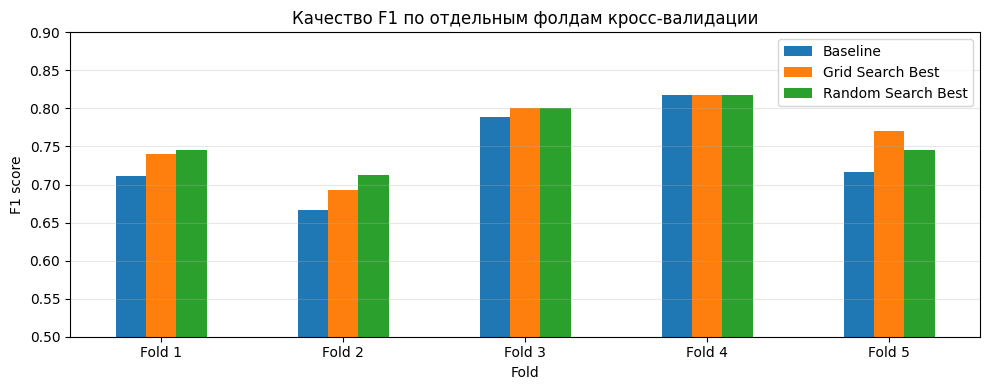

In [10]:
fold_cols = [f'split{i}_test_score' for i in range(CV_FOLDS)]

grid_best_folds = [grid.cv_results_[col][grid.best_index_] for col in fold_cols]
random_best_folds = [random_search.cv_results_[col][random_search.best_index_] for col in fold_cols]

folds_df = pd.DataFrame({
    'Fold': [f'Fold {i+1}' for i in range(CV_FOLDS)],
    'Baseline': base_cv_scores,
    'Grid Search Best': grid_best_folds,
    'Random Search Best': random_best_folds
}).set_index('Fold')

display(folds_df.T.assign(
    Mean=folds_df.mean(),
    Std=folds_df.std(ddof=0),
    Min=folds_df.min(),
    Max=folds_df.max()
))

ax = folds_df.plot(kind='bar', figsize=(10, 4), rot=0)
ax.set_title("Качество F1 по отдельным фолдам кросс-валидации")
ax.set_ylabel("F1 score")
ax.set_ylim(0.5, 0.9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

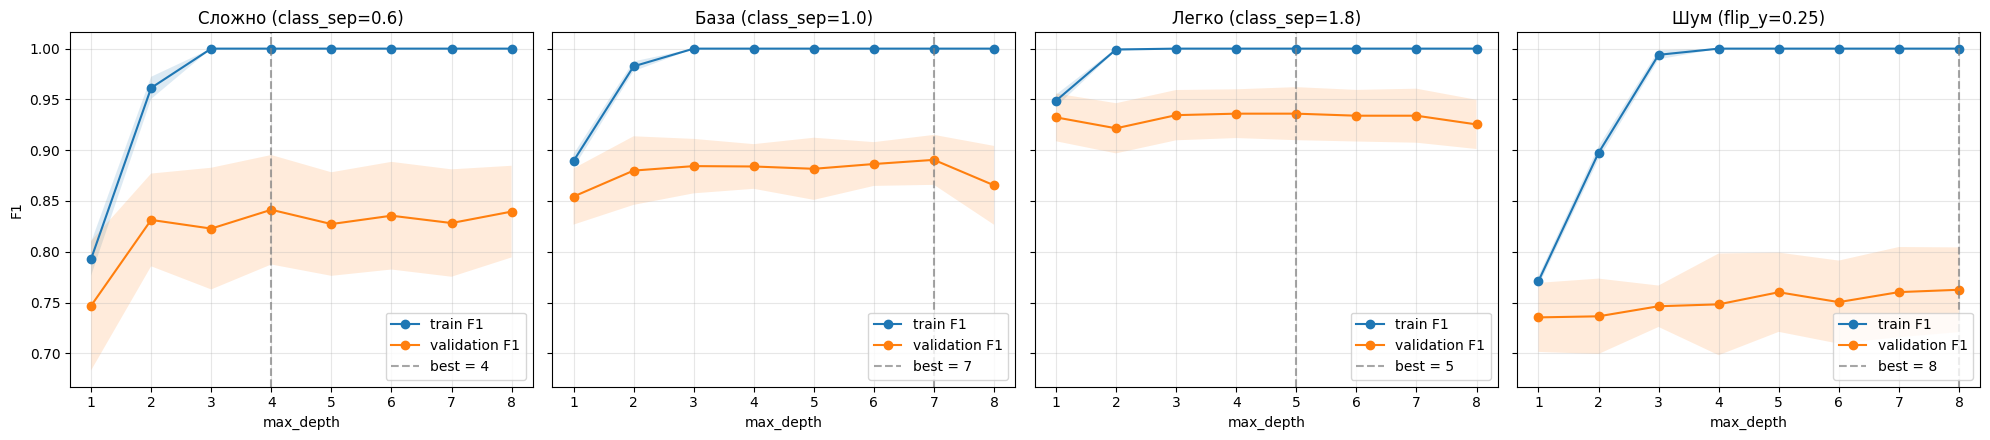

,Сценарий,class_sep,flip_y,best_max_depth,best_cv_f1,std_cv_f1,test_f1
0,Сложно (class_sep=0.6),0.6,0.05,4,0.8414,0.0539,0.8217
1,База (class_sep=1.0),1.0,0.05,7,0.8905,0.0246,0.8759
2,Легко (class_sep=1.8),1.8,0.05,5,0.9360,0.0261,0.9143
3,Шум (flip_y=0.25),1.0,0.25,8,0.7626,0.0417,0.7121


In [13]:
scenarios = [
    ("Сложно (class_sep=0.6)", {"class_sep": 0.6, "flip_y": 0.05}),
    ("База (class_sep=1.0)",   {"class_sep": 1.0, "flip_y": 0.05}),
    ("Легко (class_sep=1.8)",  {"class_sep": 1.8, "flip_y": 0.05}),
    ("Шум (flip_y=0.25)",      {"class_sep": 1.0, "flip_y": 0.25}),
]

depth_range = np.arange(1, 9)
synth_rows = []

fig, axes = plt.subplots(1, len(scenarios), figsize=(20, 4.5), sharey=True)

for ax, (title, gen_params) in zip(axes, scenarios):
    X_syn, y_syn = make_classification(
        n_samples=1000,
        n_features=12,
        n_informative=6,
        n_redundant=2,
        weights=[0.65, 0.35],
        random_state=RANDOM_STATE,
        **gen_params,
    )

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_syn, y_syn, test_size=TEST_SIZE, stratify=y_syn, random_state=RANDOM_STATE
    )

    gb_syn = GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, random_state=RANDOM_STATE
    )

    train_scores, val_scores = validation_curve(
        gb_syn,
        X_tr,
        y_tr,
        param_name="max_depth",
        param_range=depth_range,
        cv=CV_FOLDS,
        scoring="f1",
        n_jobs=-1,
    )

    tr_mean, tr_std = train_scores.mean(axis=1), train_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)
    best_idx = int(np.argmax(val_mean))
    best_depth = int(depth_range[best_idx])

    best_model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=best_depth,
        random_state=RANDOM_STATE,
    ).fit(X_tr, y_tr)

    test_f1 = f1_score(y_te, best_model.predict(X_te))

    synth_rows.append({
        "Сценарий": title,
        "class_sep": gen_params["class_sep"],
        "flip_y": gen_params["flip_y"],
        "best_max_depth": best_depth,
        "best_cv_f1": round(val_mean[best_idx], 4),
        "std_cv_f1": round(val_std[best_idx], 4),
        "test_f1": round(test_f1, 4),
    })

    ax.plot(depth_range, tr_mean, marker="o", label="train F1")
    ax.fill_between(depth_range, tr_mean - tr_std, tr_mean + tr_std, alpha=0.15)
    ax.plot(depth_range, val_mean, marker="o", label="validation F1")
    ax.fill_between(depth_range, val_mean - val_std, val_mean + val_std, alpha=0.15)
    ax.axvline(best_depth, color="grey", linestyle="--", alpha=0.7, label=f"best = {best_depth}")

    ax.set_title(title)
    ax.set_xlabel("max_depth")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right")

axes[0].set_ylabel("F1")
plt.tight_layout()
plt.show()

synth_summary_df = pd.DataFrame(synth_rows)
synth_summary_df

In [12]:
def evaluate_final(name, model, cv_mean, cv_std, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    return {
        'model': name,
        'cv_f1_mean': cv_mean,
        'cv_f1_std': cv_std,
        'f1_test': f1_score(y_test, pred_test, zero_division=0),
        'f1_train': f1_score(y_train, pred_train, zero_division=0),
        'accuracy_test': accuracy_score(y_test, pred_test),
        'precision_test': precision_score(y_test, pred_test, zero_division=0),
        'recall_test': recall_score(y_test, pred_test, zero_division=0),
    }

final_models = [
    ('Baseline GB', gb_base, base_cv_scores.mean(), base_cv_scores.std()),
    ('Grid Search GB', grid.best_estimator_, grid.best_score_, grid.cv_results_['std_test_score'][grid.best_index_]),
    ('Random Search GB', random_search.best_estimator_, random_search.best_score_, random_search.cv_results_['std_test_score'][random_search.best_index_]),
]

final_results = pd.DataFrame([
    evaluate_final(name, model, cv_m, cv_s, X_train, y_train, X_test, y_test)
    for name, model, cv_m, cv_s in final_models
])

final_results

,model,cv_f1_mean,cv_f1_std,f1_test,f1_train,accuracy_test,precision_test,recall_test
0,Baseline GB,0.740472,0.055189,0.724409,0.808594,0.804469,0.793103,0.666667
1,Grid Search GB,0.764527,0.044377,0.736842,0.783734,0.804469,0.765625,0.710145
2,Random Search GB,0.764392,0.038815,0.751880,0.785185,0.815642,0.781250,0.724638
